<a href="https://colab.research.google.com/github/nirajan-sah/ML/blob/Pytorch/CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import libraries

In [1]:
import torch
from torch import nn

import torchvision
from torchvision import datasets
from torchvision.transforms import ToTensor

import matplotlib.pyplot as plt

# Import data and set data and device

In [2]:
train_data = datasets.FashionMNIST(
    root = "data",
    train = True,
    download = True,
    transform=ToTensor(),
    target_transform=None
)
test_data = datasets.FashionMNIST(
    root = "data",
    train = False,
    download = True,
    transform = ToTensor(),
    target_transform = None
)

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 206kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.84MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 29.6MB/s]


In [3]:
class_names = train_data.classes
class_names, len(class_names)

(['T-shirt/top',
  'Trouser',
  'Pullover',
  'Dress',
  'Coat',
  'Sandal',
  'Shirt',
  'Sneaker',
  'Bag',
  'Ankle boot'],
 10)

# Prepare Data in Batches

In [4]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_dataloader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_dataloader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle = False
)


In [5]:
device = "cuda" if torch.cuda.is_available() else "cpu"

# Create CNN model

In [6]:
class FashionMNISTModelCNN(nn.Module):
  def __init__(self,
               input_shape: int, hidden_layer: int, output_shape: int):
    super().__init__()

    self.conv_block_1 = nn.Sequential(
        nn.Conv2d(in_channels=input_shape,
                  out_channels=hidden_layer,
                  kernel_size=3,
                  padding=1,
                  stride=1),
        nn.ReLU(),
        nn.Conv2d(in_channels=hidden_layer,
                  out_channels=hidden_layer,
                  kernel_size=3,
                  padding=1,
                  stride=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2)
    )

    self.conv_block_2 = nn.Sequential(
        nn.Conv2d(in_channels=hidden_layer,
                  out_channels=hidden_layer,
                  kernel_size=3,
                  padding=1,
                  stride=1),
        nn.ReLU(),
        nn.Conv2d(in_channels=hidden_layer,
                  out_channels=hidden_layer,
                  kernel_size=3,
                  padding=1,
                  stride=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2)
    )

    self.classifier = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=hidden_layer*7*7,
                  out_features=output_shape)
    )

  def forward(self, x):
    x = self.conv_block_1(x)

    x = self.conv_block_2(x)

    x = self.classifier(x)

    return x

# Initialize the model

In [7]:
torch.manual_seed(42)

model = FashionMNISTModelCNN(input_shape=1,
                             hidden_layer=32,
                             output_shape=len(class_names)).to(device)

# Initializing loss and optimizer

In [8]:
import requests
from pathlib import Path

# Download helper functions from Learn PyTorch repo (if not already downloaded)
if Path("helper_functions.py").is_file():
  print("helper_functions.py already exists, skipping download")
else:
  print("Downloading helper_functions.py")
  # Note: you need the "raw" GitHub URL for this to work
  request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
  with open("helper_functions.py", "wb") as f:
    f.write(request.content)

In [99]:
from helper_functions import accuracy_fn

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(),
                            lr=0.0001)

# Functionize train and test loop

In [100]:
def train_loop(model: torch.nn.Module,
          dataloader: torch.utils.data,
          loss_fn: torch.nn.Module,
          optimizer: torch.optim.Optimizer,
          accuracy_fn,
          device: torch.device = device):
  train_loss, train_acc = 0., 0.
  model.train()

  for batch, (X, y )in enumerate(dataloader):
    X, y = X.to(device), y.to(device)

    train_pred = model(X)

    loss = loss_fn(train_pred, y)

    train_loss += loss
    train_acc += accuracy_fn(y_true=y, y_pred=train_pred.argmax(dim=1))

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

  print(f"Train loss:{train_loss/len(dataloader):.4f} | Train Acc:{train_acc/len(dataloader):.2f}%")

def test_loop(model: torch.nn.Module,
              dataloader: torch.utils.data,
              loss_fn: torch.nn.Module,
              accuracy_fn,
              device: torch.device = device
              ):
  test_loss, test_acc = 0., 0.
  model.eval()

  with torch.inference_mode():
    for X, y in dataloader:
      X, y = (t.to(device) for t in (X, y))
      test_pred = model(X)

      test_loss += loss_fn(test_pred, y)
      test_acc += accuracy_fn(y_true=y, y_pred=test_pred.argmax(dim=1))

  print(f"Test loss:{test_loss/len(dataloader):.4f} | Test Accuracy:{test_acc/len(dataloader):2f}%")


# Train Model

In [101]:
from tqdm.auto import tqdm

In [102]:
torch.manual_seed(42)

# Measure time
from timeit import default_timer as timer
train_time_start_model_2 = timer()

# Train and test model
epochs = 5
for epoch in tqdm(range(epochs)):
    print(f"Epoch: {epoch}\n---------")
    train_loop(
        model=model,
        dataloader=train_dataloader,
        loss_fn=loss_fn,
        optimizer=optimizer,
        accuracy_fn=accuracy_fn,
        device=device
    )
    test_loop(dataloader=test_dataloader,
        model=model,
        loss_fn=loss_fn,
        accuracy_fn=accuracy_fn,
        device=device
    )

train_time_end_model_2 = timer()
print(f"The total time taken in {device} is {train_time_end_model_2-train_time_start_model_2}")

  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 0
---------
Train loss:0.0261 | Train Acc:99.44%
Test loss:0.3572 | Test Accuracy:91.972843%
Epoch: 1
---------
Train loss:0.0261 | Train Acc:99.44%
Test loss:0.3573 | Test Accuracy:91.962859%
Epoch: 2
---------
Train loss:0.0261 | Train Acc:99.45%
Test loss:0.3574 | Test Accuracy:91.972843%
Epoch: 3
---------
Train loss:0.0260 | Train Acc:99.44%
Test loss:0.3575 | Test Accuracy:91.972843%
Epoch: 4
---------
Train loss:0.0260 | Train Acc:99.45%
Test loss:0.3576 | Test Accuracy:91.962859%
The total time taken in cuda is 59.314400878000015


In [103]:
model_saved = torch.load('cnn_model.pth')

# Make prediction on small dataset

In [104]:
def make_prediction(model: torch.nn.Module,
                    samples: list,
                    device: torch.device = device):
  pred_probs=[]

  model.eval()

  with torch.inference_mode():
    for sample in samples:
      sample = torch.unsqueeze(sample, dim=0).to(device)

      pred_logits = model(sample)

      pred_prob = torch.softmax(pred_logits.squeeze(), dim=0)

      pred_probs.append(pred_prob.cpu())

  return torch.stack(pred_probs)

In [105]:
import random

test_samples = []
test_labels = []

for sample, label in random.sample(list(test_data), k = 16):
  test_samples.append(sample)
  test_labels.append(label)


# Plot the prediction

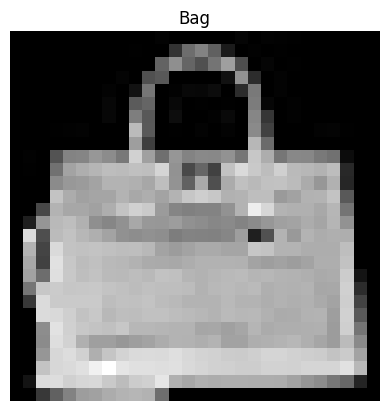

In [106]:
plt.imshow(test_samples[0].squeeze(dim=0), cmap="grey")
plt.title(class_names[test_labels[0]])
plt.axis(False)
plt.show()

In [107]:
pred_prob = make_prediction(model=model,
                samples=test_samples,
                )

In [108]:
test_pred = pred_prob.argmax(dim=1)

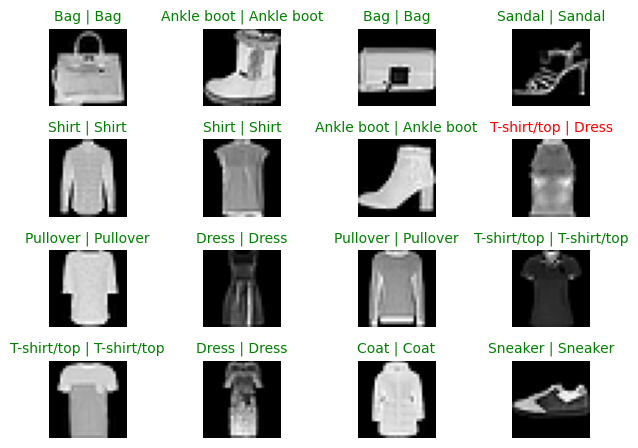

In [111]:
plt.figsize=(20,20)
rows, cols = 4, 4

for i in range(1, rows*cols+1):
  plt.subplot(rows, cols, i)
  plt.tight_layout(pad=1.0, h_pad=1.0, w_pad=1.0)
  plt.imshow(test_samples[i-1].squeeze(), cmap="grey")
  true_label = test_labels[i-1]
  pred_label = test_pred[i-1]
  title_text = f"{class_names[true_label]} | {class_names[pred_label]}"
  if true_label == pred_label:
    plt.title(title_text, fontsize = 10, c='g')
  else:
    plt.title(title_text, fontsize = 10, c='r')
  plt.axis(False)


# Make prediction on entire dataset

In [118]:
test_preds = []

model.eval()

with torch.inference_mode():
  for X, y in tqdm(test_dataloader, desc="Making prediction"):
    X, y = X.to(device), y.to(device)
    test_logits = model(X)
    test_pred = torch.softmax(test_logits.squeeze(), dim=0).argmax(dim=1)
    test_preds.append(test_pred.cpu())

test_preds_tensor = torch.cat(test_preds)
test_preds_tensor[:10]

Making prediction:   0%|          | 0/313 [00:00<?, ?it/s]

tensor([9, 2, 1, 1, 0, 1, 4, 6, 5, 7])

In [123]:
!pip install torchmetrics

In [124]:
!pip install mlxtend

In [127]:
import torchmetrics, mlxtend

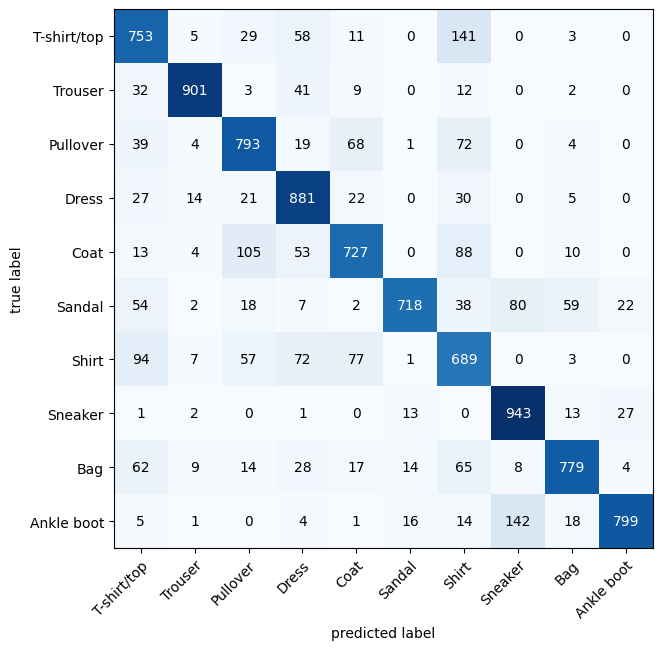

In [139]:
from torchmetrics import ConfusionMatrix
from mlxtend.plotting import plot_confusion_matrix

# 2. Setup confusion matrix instance and compare predictions to targets
confmat = ConfusionMatrix(num_classes=len(class_names), task='multiclass')
confmat_tensor = confmat(preds=test_preds_tensor,
                         target=test_data.targets)

# 3. Plot the confusion matrix
fig, ax = plot_confusion_matrix(
    conf_mat=confmat_tensor.numpy(), # matplotlib likes working with NumPy
    class_names=class_names, # turn the row and column labels into class names
    figsize=(10, 7)
);

In [141]:
from pathlib import Path

# Create models directory (if it doesn't already exist), see: https://docs.python.org/3/library/pathlib.html#pathlib.Path.mkdir
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, # create parent directories if needed
                 exist_ok=True # if models directory already exists, don't error
)

# Create model save path
MODEL_NAME = "03_pytorch_computer_vision_model_2.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

# Save the model state dict
print(f"Saving model to: {MODEL_SAVE_PATH}")
torch.save(obj=model.state_dict(), # only saving the state_dict() only saves the learned parameters
           f=MODEL_SAVE_PATH)

Saving model to: models/03_pytorch_computer_vision_model_2.pth
